# Demo: predicting football matches and BTTS

This notebook is the proof of concept for my *Introduction to Artificial Intelligence* project.
It walks through the whole idea on real data, step by step:

1. the data and what it looks like,
2. Elo ratings (one strength number per team),
3. how the models are tested (walk-forward, no peeking into the future),
4. five models compared on the match result, including a small neural network (MLP),
5. the same for both teams to score (BTTS),
6. what the decision trees in gradient boosting actually use,
7. why the simpler model (logistic regression) still won,
8. one match through the Poisson goals model, from expected goals to every exact score.

All the heavy lifting is done by the code in `src/`. The notebook only calls it and shows the results.

**Before running:** download the data once from the project root with `python -m src.load_domestic_leagues`.
Then run all cells (about 3-5 minutes on a laptop).

In [1]:
import os
from pathlib import Path

# Run from the project root, so the paths in src/ work (the notebook lives in notebooks/)
if Path.cwd().name == "notebooks":
    os.chdir("..")

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

from src.backtest import FIRST_TRAIN_SEASON, LEAGUES, TEST_SEASONS
from src.elo import EloParams, compute_elo
from src.evaluate_models import (base_rates, boosting, load_data, logistic,
                                 walk_forward, walk_forward_goals)
from src.features import feature_groups
from src.goals_model import goals_regressor, markets, score_table
from src.metrics import accuracy, brier, log_loss, market_probabilities, rps

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

LEAGUE_NAMES = {"E0": "Premier League", "SP1": "LaLiga", "I1": "Serie A",
                "D1": "Bundesliga", "F1": "Ligue 1", "POL": "Ekstraklasa"}
COLORS = {"base rates": "#b8b8b8", "Elo only": "#8fb3d9", "logistic regression": "#2f6db5",
          "gradient boosting": "#3a9e5f", "neural network (MLP)": "#e08a2e",
          "Poisson goals model": "#8e44ad", "bookmakers": "#222222"}

## 1. The data

Results, goals, shots and shots on target from [football-data.co.uk](https://www.football-data.co.uk),
season 2016-17 up to today. The bookmaker odds are kept only as a benchmark, they never go into the models.

`load_data()` does three things: computes Elo for every team, builds the pre-match features
and keeps the six leagues we predict. Every feature uses only matches played **before** kick-off.

In [2]:
df = load_data()
groups = feature_groups(LEAGUES)
all_columns = [c for columns in groups.values() for c in columns]
test = df["season"].isin(TEST_SEASONS).to_numpy()

print(f"{len(df):,} matches from {FIRST_TRAIN_SEASON}-{FIRST_TRAIN_SEASON + 1} on, "
      f"{test.sum():,} of them in the test seasons")
print(f"{len(all_columns)} features in {len(groups)} groups: {', '.join(groups)}")

summary = (df.assign(league=df["league"].map(LEAGUE_NAMES))
             .groupby("league")
             .agg(matches=("home_team", "size"),
                  home_win=("outcome", lambda s: (s == 0).mean()),
                  draw=("outcome", lambda s: (s == 1).mean()),
                  away_win=("outcome", lambda s: (s == 2).mean()),
                  btts=("btts", "mean"),
                  goals_per_match=("home_goals", lambda s: (s + df.loc[s.index, "away_goals"]).mean())))
summary

19,336 matches from 2017-2018 on, 10,438 of them in the test seasons
59 features in 10 groups: elo, league, form, scoring, shots, venue, recent, h2h, league_trend, day


,matches,home_win,draw,away_win,btts,goals_per_match
league,,,,,,
Bundesliga,2826,0.4381,0.2484,0.3135,0.5920,3.1313
Ekstraklasa,2773,0.4439,0.2658,0.2903,0.5341,2.6621
LaLiga,3529,0.4528,0.2647,0.2825,0.5123,2.5956
Ligue 1,3178,0.4346,0.2524,0.3131,0.5337,2.7495
Premier League,3510,0.4402,0.2348,0.3251,0.5285,2.8353
Serie A,3520,0.4139,0.2574,0.3287,0.5364,2.7324


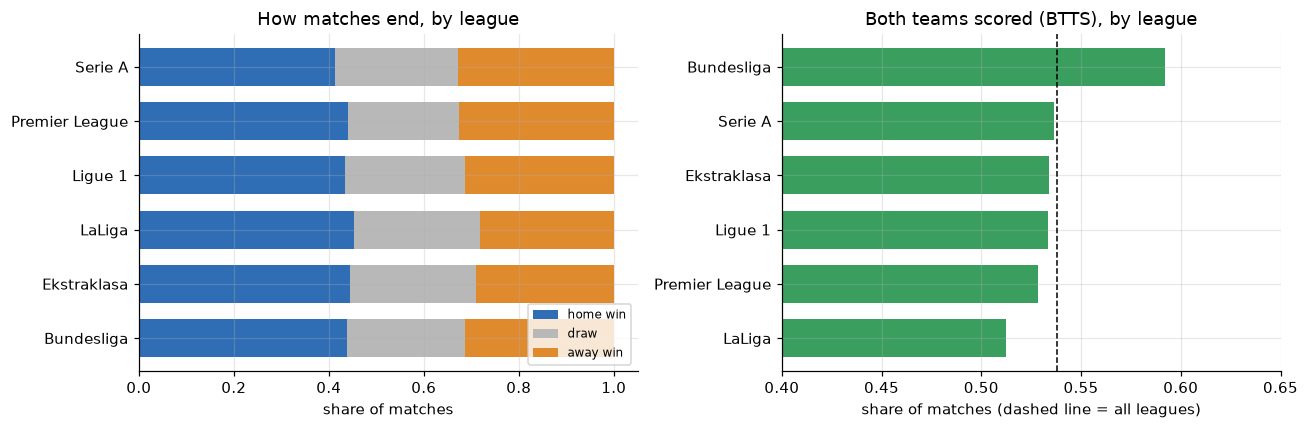

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

shares = summary[["home_win", "draw", "away_win"]]
shares.plot.barh(stacked=True, ax=axes[0], color=["#2f6db5", "#b8b8b8", "#e08a2e"], width=0.7)
axes[0].set_title("How matches end, by league")
axes[0].set_xlabel("share of matches")
axes[0].set_ylabel("")
axes[0].legend(["home win", "draw", "away win"], loc="lower right", fontsize=8)

summary["btts"].sort_values().plot.barh(ax=axes[1], color="#3a9e5f", width=0.7)
axes[1].axvline(df["btts"].mean(), color="black", linestyle="--", linewidth=1)
axes[1].set_title("Both teams scored (BTTS), by league")
axes[1].set_xlabel("share of matches (dashed line = all leagues)")
axes[1].set_ylabel("")
axes[1].set_xlim(0.4, 0.65)
plt.tight_layout()
plt.show()

Two things are worth noticing already. The home team wins in less than half of the matches,
so even the "obvious" outcome is far from certain. And BTTS is close to a coin flip in every league,
the Bundesliga being the most open one. That is why BTTS is the hard part of the project.

## 2. Elo ratings

Every team has one number. After each match the winner takes points from the loser.
A surprise win moves the ratings more than an expected one, and a big win more than a narrow one.
On top of the classic chess version the project adds home advantage, a lower start for promoted teams
and a pull back towards the league average every summer. The settings were tuned on 2019-20 and 2020-21.

Elo settings: EloParams(k=8.0, home_advantage=60.0, initial_rating=1500.0, new_team_gap=50.0, season_regression=0.2)


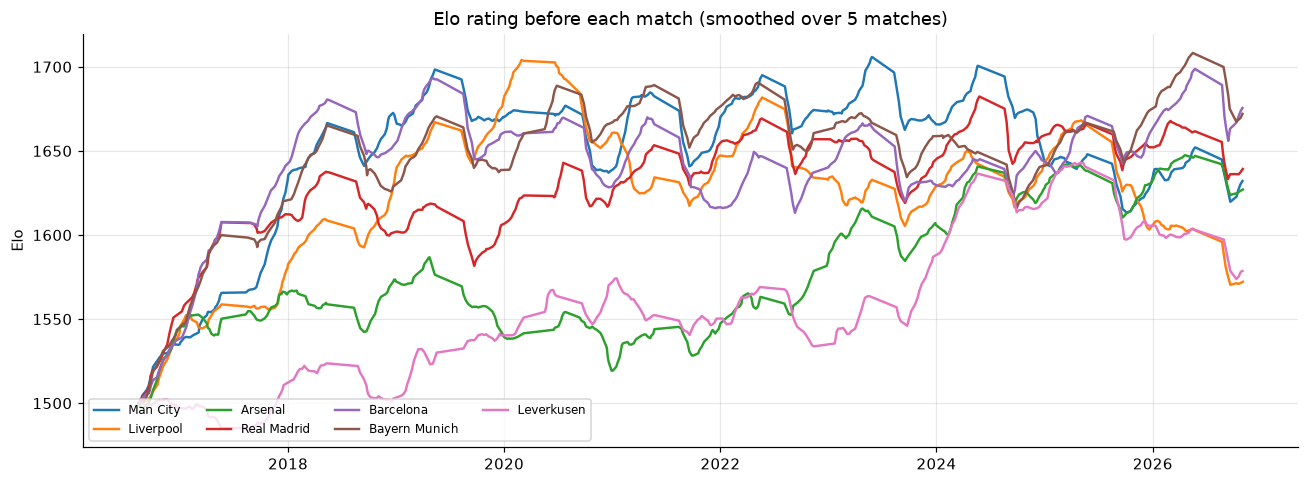

In [4]:
params = EloParams(**json.loads(Path("results/elo_params.json").read_text()))
print("Elo settings:", params)

with_elo, _ = compute_elo(pd.read_csv("data/processed/domestic_matches.csv"), params)
long = pd.concat([
    with_elo[["date", "home_team", "elo_home"]].set_axis(["date", "team", "elo"], axis=1),
    with_elo[["date", "away_team", "elo_away"]].set_axis(["date", "team", "elo"], axis=1),
]).sort_values("date")

teams = ["Man City", "Liverpool", "Arsenal", "Real Madrid", "Barcelona", "Bayern Munich", "Leverkusen"]
fig, ax = plt.subplots(figsize=(12, 4.5))
for team in teams:
    one = long[long["team"] == team]
    ax.plot(one["date"], one["elo"].rolling(5, min_periods=1).mean(), label=team, linewidth=1.6)
ax.set_title("Elo rating before each match (smoothed over 5 matches)")
ax.set_ylabel("Elo")
ax.legend(ncol=4, fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

Everyone starts at 1500 in 2016, so the first season is only a warm-up (it is never used for testing).
After that the lines follow what a fan would expect, for example Leverkusen climbing towards the 2023-24 title
and Barcelona's dip after 2019 and the comeback later. Elo alone already explains most of what the models
can predict, as the next sections show.

## 3. How the models are tested

A model that has seen the answers looks great and is useless. So every test season is predicted
only with the seasons before it, exactly like standing at the start of that season and predicting it.
This is called walk-forward testing.

In [5]:
seasons = sorted(df["season"].unique())
plan = pd.DataFrame(
    [["train" if s < t else ("TEST" if s == t else "-") for s in seasons] for t in TEST_SEASONS],
    index=[f"predicting {t}-{str(t + 1)[2:]}" for t in TEST_SEASONS],
    columns=[f"{s}-{str(s + 1)[2:]}" for s in seasons])
plan

,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
predicting 2021-22,train,train,train,train,TEST,-,-,-,-,-
predicting 2022-23,train,train,train,train,train,TEST,-,-,-,-
predicting 2023-24,train,train,train,train,train,train,TEST,-,-,-
predicting 2024-25,train,train,train,train,train,train,train,TEST,-,-
predicting 2025-26,train,train,train,train,train,train,train,train,TEST,-


**How the forecasts are scored** (lower is better for all three):

- **RPS** (ranked probability score), the standard score for home / draw / away forecasts.
  It knows the outcomes are ordered, so giving the draw 40% when the home team wins costs less than giving the away win 40%.
- **Log loss**, punishes being confident and wrong.
- **Brier score**, for yes / no questions like BTTS: the average squared gap between the forecast and what happened.

Accuracy is shown too, but it is a weak measure here. It ignores how sure the model was.

## 4. Match result: five models side by side

| Model | Idea |
|---|---|
| Elo only | logistic regression with a single feature, the Elo difference |
| Logistic regression | all features, each with a learned weight, sum turned into three probabilities |
| Gradient boosting | many small decision trees, each one fixing the mistakes of the previous ones |
| Neural network (MLP) | **new in this notebook**: two hidden layers (32 and 16 neurons), ReLU, early stopping |
| Poisson goals model | predicts expected goals of both teams, then reads 1X2 and BTTS from the table of all scores |

Base rates (always the same percentages) are the floor, the bookmakers' closing odds are the ceiling.

In [6]:
def mlp():
    """A small neural network. Inputs are scaled first, training stops when the validation loss stops improving."""
    return make_pipeline(SimpleImputer(), StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-2, learning_rate_init=1e-3,
                                       batch_size=256, max_iter=200, early_stopping=True,
                                       validation_fraction=0.15, n_iter_no_change=10, random_state=0))


outcomes = df.loc[test, "outcome"].to_numpy()
btts = df.loc[test, "btts"].to_numpy()

forecasts = {
    "base rates": walk_forward(df, ["elo_diff"], base_rates, "outcome", 3)[test],
    "Elo only": walk_forward(df, ["elo_diff"], logistic, "outcome", 3)[test],
    "logistic regression": walk_forward(df, all_columns, logistic, "outcome", 3)[test],
    "gradient boosting": walk_forward(df, all_columns, boosting, "outcome", 3)[test],
    "neural network (MLP)": walk_forward(df, all_columns, mlp, "outcome", 3)[test],
}
home_rate, away_rate = walk_forward_goals(df, all_columns)
goals = markets(home_rate[test], away_rate[test])
forecasts["Poisson goals model"] = np.column_stack([goals["home_win"], goals["draw"], goals["away_win"]])
tested = df[test]
forecasts["bookmakers"] = market_probabilities(tested["odds_home"], tested["odds_draw"], tested["odds_away"])

result_table = pd.DataFrame(
    {name: {"RPS": rps(p, outcomes), "log loss": log_loss(p, outcomes), "accuracy": accuracy(p, outcomes)}
     for name, p in forecasts.items()}).T
result_table

,RPS,log loss,accuracy
base rates,0.2294,1.0738,0.4359
Elo only,0.2032,0.9980,0.5142
logistic regression,0.2024,0.9962,0.5154
gradient boosting,0.2029,0.9975,0.5156
neural network (MLP),0.2071,1.0137,0.5034
Poisson goals model,0.2021,0.9949,0.5183
bookmakers,0.1972,0.9778,0.5295


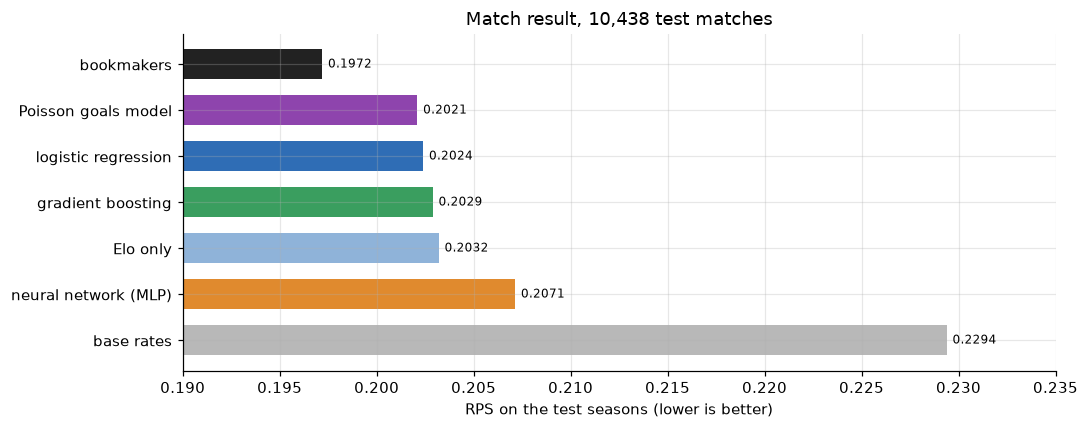

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
order = result_table.sort_values("RPS", ascending=False)
ax.barh(order.index, order["RPS"], color=[COLORS[n] for n in order.index], height=0.65)
for i, value in enumerate(order["RPS"]):
    ax.text(value + 0.0003, i, f"{value:.4f}", va="center", fontsize=8)
ax.set_xlim(0.19, 0.235)
ax.set_xlabel("RPS on the test seasons (lower is better)")
ax.set_title(f"Match result, {test.sum():,} test matches")
plt.tight_layout()
plt.show()

The big jump is from base rates to Elo. After that every model lands in a narrow band,
and the bookmakers are still ahead. The bookmakers see line-ups, injuries and the money of
thousands of bettors, so being close to them with public data only is already a fair result.

The MLP does not beat logistic regression. More on why in section 7.

## 5. Both teams to score

Same test, same features, the target is now yes / no. There are no bookmaker BTTS odds in the data,
so base rates are the only benchmark.

In [8]:
btts_forecasts = {
    "base rates": walk_forward(df, ["elo_diff"], base_rates, "btts", 2)[test][:, 1],
    "logistic regression": walk_forward(df, all_columns, logistic, "btts", 2)[test][:, 1],
    "gradient boosting": walk_forward(df, all_columns, boosting, "btts", 2)[test][:, 1],
    "neural network (MLP)": walk_forward(df, all_columns, mlp, "btts", 2)[test][:, 1],
    "Poisson goals model": goals["btts_yes"],
}


def btts_row(p):
    both = np.column_stack([1 - p, p])
    return {"Brier": brier(p, btts), "log loss": log_loss(both, btts), "accuracy": accuracy(both, btts),
            "lowest forecast": p.min(), "highest forecast": p.max()}


btts_table = pd.DataFrame({name: btts_row(p) for name, p in btts_forecasts.items()}).T
btts_table

,Brier,log loss,accuracy,lowest forecast,highest forecast
base rates,0.2482,0.6896,0.5444,0.5267,0.5356
logistic regression,0.2480,0.6891,0.5304,0.2587,0.7481
gradient boosting,0.2481,0.6894,0.5339,0.3056,0.7028
neural network (MLP),0.2517,0.6970,0.5311,0.1293,0.8478
Poisson goals model,0.2471,0.6874,0.5382,0.3169,0.7207


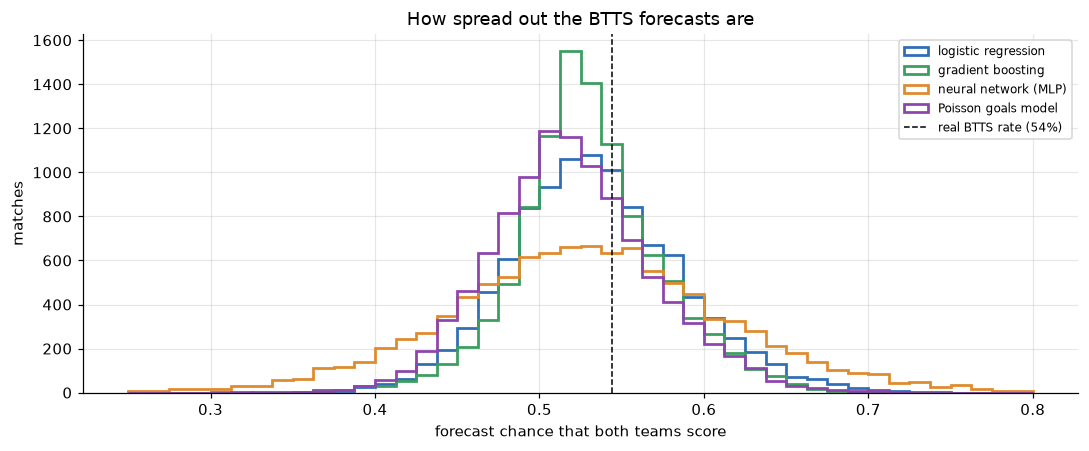

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.linspace(0.25, 0.80, 45)
for name in ["logistic regression", "gradient boosting", "neural network (MLP)", "Poisson goals model"]:
    ax.hist(btts_forecasts[name], bins=bins, histtype="step", linewidth=1.8, color=COLORS[name], label=name)
ax.axvline(btts.mean(), color="black", linestyle="--", linewidth=1, label=f"real BTTS rate ({btts.mean():.0%})")
ax.set_xlabel("forecast chance that both teams score")
ax.set_ylabel("matches")
ax.set_title("How spread out the BTTS forecasts are")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Most BTTS forecasts sit between 45% and 65%. Logistic regression and boosting end up about level with the
base rate on the Brier score, and the MLP is worse. Only the Poisson goals model beats the base rate clearly,
which is why the live website uses it for BTTS. The useful part is the tail: when the forecast is clearly above 60%,
BTTS really does happen more often (see the calibration chart in section 7).

## 6. Inside gradient boosting: what do the trees look at?

Gradient boosting is a sum of many small decision trees. To see what they use,
we train it on all seasons before 2025-26 and then shuffle one feature at a time on 2025-26.
If the log loss gets much worse after shuffling, the trees relied on that feature.
This is called permutation importance. It is fairer than counting splits, because it is measured on matches the model has not seen.

trees in the model: 32 rounds x 3 classes = 96 trees


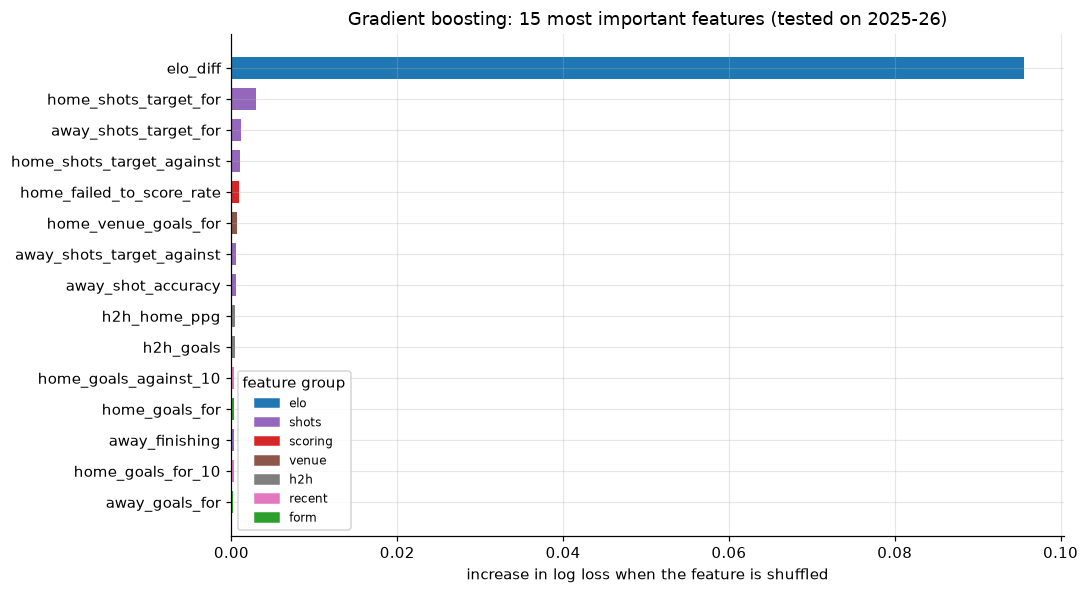

In [10]:
last = TEST_SEASONS[-1]
train_rows = ((df["season"] >= FIRST_TRAIN_SEASON) & (df["season"] < last)).to_numpy()
test_rows = (df["season"] == last).to_numpy()
usable = [c for c in all_columns if df.loc[train_rows, c].notna().any()]
X_train, y_train = df.loc[train_rows, usable], df.loc[train_rows, "outcome"]
X_last, y_last = df.loc[test_rows, usable], df.loc[test_rows, "outcome"]

tree_model = boosting().fit(X_train, y_train)
print(f"trees in the model: {tree_model.n_iter_} rounds x 3 classes = {tree_model.n_iter_ * 3} trees")

importance = permutation_importance(tree_model, X_last, y_last, scoring="neg_log_loss",
                                    n_repeats=5, random_state=0, n_jobs=-1)
importance = pd.Series(importance.importances_mean, index=usable).sort_values(ascending=False)

group_of = {c: g for g, cols in groups.items() for c in cols}
top = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
palette = dict(zip(groups, plt.cm.tab10.colors))
ax.barh(top.index, top.values, color=[palette[group_of[c]] for c in top.index], height=0.7)
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[g]) for g in dict.fromkeys(group_of[c] for c in top.index[::-1])]
ax.legend(handles, list(dict.fromkeys(group_of[c] for c in top.index[::-1])), title="feature group", fontsize=8)
ax.set_xlabel("increase in log loss when the feature is shuffled")
ax.set_title(f"Gradient boosting: 15 most important features (tested on {last}-{str(last + 1)[2:]})")
plt.tight_layout()
plt.show()

In [11]:
by_group = importance.groupby(importance.index.map(group_of)).sum().sort_values(ascending=False)
by_group.to_frame("summed importance")

,summed importance
elo,9.5607e-02
shots,6.2482e-03
h2h,7.9304e-04
scoring,5.9489e-04
venue,5.6031e-04
day,1.0734e-04
league,-2.6707e-05
recent,-1.7286e-04
form,-4.8597e-04
league_trend,-6.4070e-04


Elo difference is far ahead of everything else. Second are the shot features, mainly shots on target
made by each team. The other groups are close to zero. That does not mean form or venue are useless,
they mostly repeat what Elo and shots already say, so shuffling one of them alone changes little.
This matches the step-by-step test in `src/evaluate_models.py`, where adding shots gave the biggest gain after Elo.

### One tree, small enough to read

A single tree of depth 3 trained on the same data. Gradient boosting builds hundreds of trees like
this one, each fitted to the errors left by the previous ones.

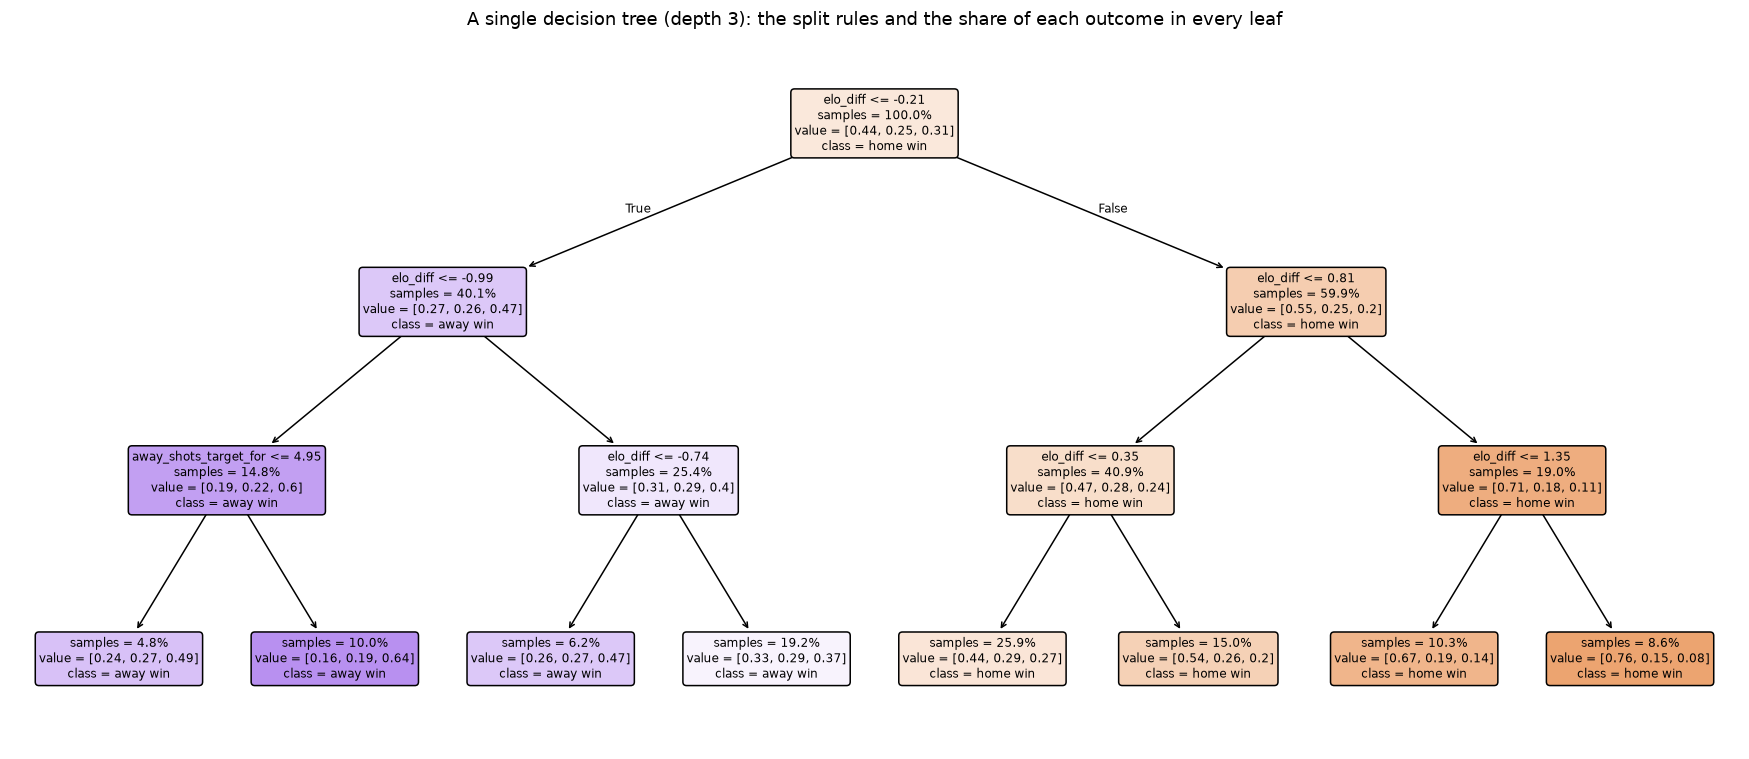

single tree RPS on 2025-26: 0.2064


In [12]:
small_tree = make_pipeline(SimpleImputer(), DecisionTreeClassifier(max_depth=3, min_samples_leaf=300, random_state=0))
small_tree.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(small_tree[-1], feature_names=usable, class_names=["home win", "draw", "away win"],
          filled=True, rounded=True, impurity=False, proportion=True, precision=2, fontsize=8, ax=ax)
ax.set_title("A single decision tree (depth 3): the split rules and the share of each outcome in every leaf")
plt.tight_layout()
plt.show()

single = small_tree.predict_proba(X_last)
print(f"single tree RPS on {last}-{str(last + 1)[2:]}: {rps(single, y_last.to_numpy()):.4f}")

Almost every split is on the Elo difference. The only other feature that makes it into the tree is
the away team's shots on target. A lone tree can only give eight different forecasts (one per leaf),
so on its own it is clearly worse than the full model.

## 7. Why did the simpler model win?

Gradient boosting and the MLP can learn curves and interactions between features. Logistic regression
can only add the features up with weights. And yet logistic regression is at least as good. Two checks:

1. **Gap between training and test.** A big gap means the model learned noise from the training seasons.
2. **Calibration.** When the model says 60%, does it happen about 60% of the time?

In [13]:
rows = []
for name, make in [("logistic regression", logistic), ("gradient boosting", boosting), ("neural network (MLP)", mlp)]:
    model = make().fit(X_train, y_train)
    p_train, p_test = model.predict_proba(X_train), model.predict_proba(X_last)
    rows.append({"model": name,
                 "RPS train": rps(p_train, y_train.to_numpy()), "RPS test": rps(p_test, y_last.to_numpy()),
                 "log loss train": log_loss(p_train, y_train.to_numpy()),
                 "log loss test": log_loss(p_test, y_last.to_numpy())})
gap = pd.DataFrame(rows).set_index("model")
gap["log loss gap"] = gap["log loss test"] - gap["log loss train"]
gap

,RPS train,RPS test,log loss train,log loss test,log loss gap
model,,,,,
logistic regression,0.2009,0.2039,0.9865,1.0032,0.0166
gradient boosting,0.1959,0.2051,0.9632,1.0033,0.0400
neural network (MLP),0.2002,0.2081,0.9818,1.0165,0.0347


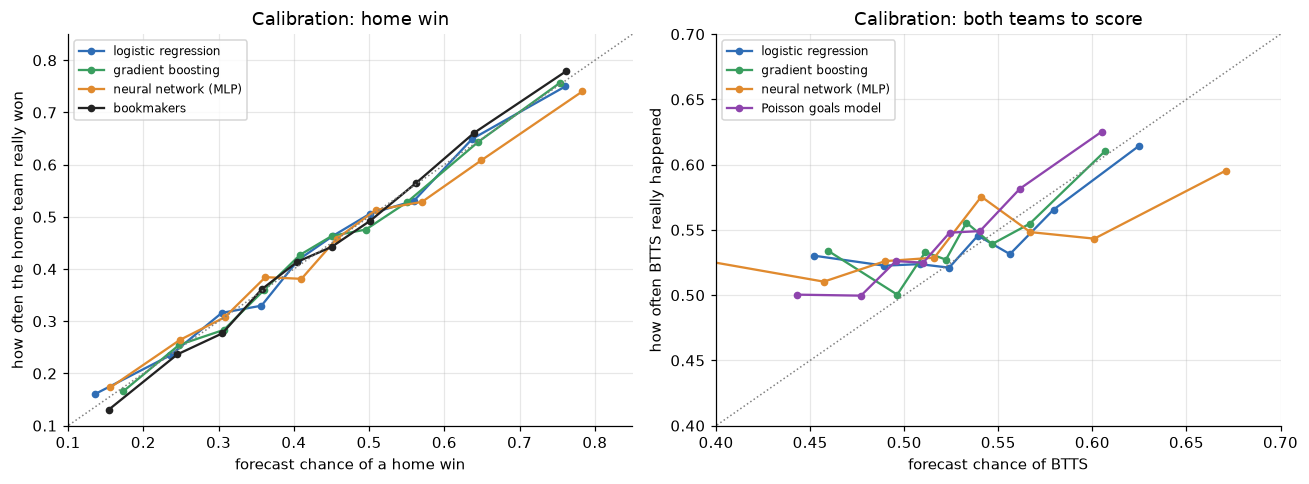

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
home_won = (outcomes == 0).astype(int)
for name in ["logistic regression", "gradient boosting", "neural network (MLP)", "bookmakers"]:
    real, predicted = calibration_curve(home_won, forecasts[name][:, 0], n_bins=10, strategy="quantile")
    axes[0].plot(predicted, real, marker="o", markersize=4, color=COLORS[name], label=name)
axes[0].plot([0, 1], [0, 1], color="grey", linestyle=":", linewidth=1)
axes[0].set(xlim=(0.1, 0.85), ylim=(0.1, 0.85), xlabel="forecast chance of a home win",
            ylabel="how often the home team really won", title="Calibration: home win")
axes[0].legend(fontsize=8)

for name in ["logistic regression", "gradient boosting", "neural network (MLP)", "Poisson goals model"]:
    real, predicted = calibration_curve(btts, btts_forecasts[name], n_bins=8, strategy="quantile")
    axes[1].plot(predicted, real, marker="o", markersize=4, color=COLORS[name], label=name)
axes[1].plot([0, 1], [0, 1], color="grey", linestyle=":", linewidth=1)
axes[1].set(xlim=(0.4, 0.7), ylim=(0.4, 0.7), xlabel="forecast chance of BTTS",
            ylabel="how often BTTS really happened", title="Calibration: both teams to score")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**What this shows, in short:**

- The signal in football data is weak and mostly "linear". A stronger team (higher Elo, more shots on target)
  wins more often, roughly in proportion to how much stronger it is. Logistic regression captures exactly this.
- The flexible models do learn something extra on the training seasons, but a lot of it is noise.
  A single match has a huge random part (a deflection, a red card, a penalty), so patterns found in 15,000 matches
  do not always repeat in the next season. The train-test gap above is the sign of that.
- For the match result all three models are well calibrated, almost as well as the bookmakers.
  So the flexible models do not lose because they are over-confident, they simply have nothing extra to find
  with these features. For BTTS the picture is weaker: the lowest forecasts are too low, the real rate there is still around 50%.
- Features matter more than the algorithm. Shots on target helped more than switching from
  logistic regression to boosting or to a neural network. The same conclusion appears in the
  2017 Soccer Prediction Challenge papers and in the review by Bunker and Susnjak (2022).

That is why the live website uses logistic regression for the match result and the Poisson goals model for BTTS:
they are as good as the complex models, faster to retrain every morning, and easy to explain.

## 8. One match through the Poisson goals model

The goals model does not predict "home win" directly. It predicts two numbers, the expected goals of
each team, and assumes both teams score like independent Poisson processes. From that we get the chance of
every exact score, and every market (1X2, BTTS, over 2.5) is just a sum over that table.

Below: the most recent match in the data between two of the strongest teams of its league.

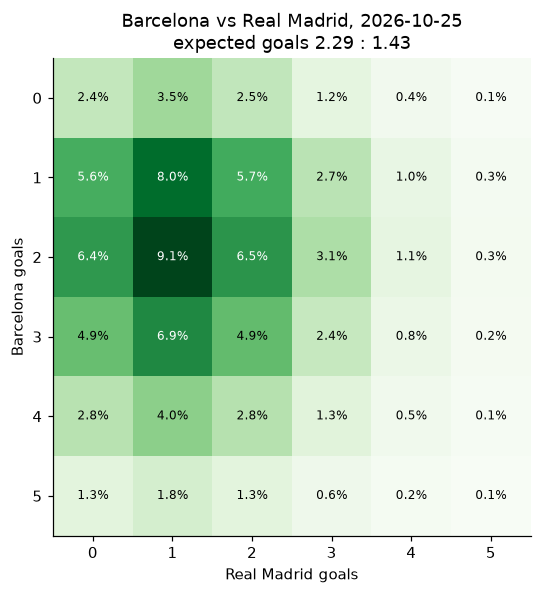

home win 56.8% | draw 19.8% | away win 23.4%
BTTS yes 68.3% | over 2.5 goals 71.7%
real result: 1-2


In [15]:
final_train = (df["season"] >= FIRST_TRAIN_SEASON).to_numpy()
usable_all = [c for c in all_columns if df.loc[final_train, c].notna().any()]
last_season = df[df["season"] == df["season"].max()]
pick = last_season.loc[(last_season["elo_home"] + last_season["elo_away"]).idxmax()]

home_model = goals_regressor().fit(df.loc[train_rows, usable_all], df.loc[train_rows, "home_goals"])
away_model = goals_regressor().fit(df.loc[train_rows, usable_all], df.loc[train_rows, "away_goals"])
row = df.loc[[pick.name], usable_all]
lam_home, lam_away = home_model.predict(row)[0], away_model.predict(row)[0]

table = score_table([lam_home], [lam_away])[0][:6, :6]
m = markets([lam_home], [lam_away])

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(table, cmap="Greens")
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{table[i, j]:.1%}", ha="center", va="center", fontsize=8,
                color="white" if table[i, j] > table.max() * 0.6 else "black")
ax.set_xticks(range(6)), ax.set_yticks(range(6))
ax.set_xlabel(f"{pick['away_team']} goals"), ax.set_ylabel(f"{pick['home_team']} goals")
ax.grid(False)
ax.set_title(f"{pick['home_team']} vs {pick['away_team']}, {pd.Timestamp(pick['date']).date()}\n"
             f"expected goals {lam_home:.2f} : {lam_away:.2f}")
plt.tight_layout()
plt.show()

print(f"home win {m['home_win'][0]:.1%} | draw {m['draw'][0]:.1%} | away win {m['away_win'][0]:.1%}")
print(f"BTTS yes {m['btts_yes'][0]:.1%} | over 2.5 goals {m['over_2_5'][0]:.1%}")
print(f"real result: {int(pick['home_goals'])}-{int(pick['away_goals'])}")

## 9. Summary

- Elo with a few honest features (form, shots, venue) gets within about 0.005 RPS of the bookmakers' closing odds,
  using only free public data.
- Gradient boosting and a small neural network were tested and are not better than logistic regression here.
  The data has a weak, mostly linear signal and a lot of randomness, so extra flexibility mostly fits noise.
- BTTS is close to a coin flip. The Poisson goals model is the best of the tested models and finds the small
  group of matches where both teams scoring is clearly more likely.
- Next steps: line-ups and coach changes, the Champions League, and a Bayesian hierarchical goals model.